In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
log_reg = pd.read_csv(
    "../results/logistic_regression_metrics.csv"
)

svm = pd.read_csv(
    "../results/svm_metrics.csv"
)

In [4]:
distilbert = pd.DataFrame([{
    "Model": "DistilBERT",
    "Accuracy": 0.933567,
    "Precision": 0.925134,
    "Recall": 0.936055,
    "F1 Score": 0.930562
}])

In [5]:
comparison = pd.concat(
    [log_reg, svm, distilbert],
    ignore_index=True
)

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.846550,0.830533,0.850959,0.840622
1,Linear SVM,0.848421,0.832773,0.852435,0.842489
2,DistilBERT,0.933567,0.925134,0.936055,0.930562


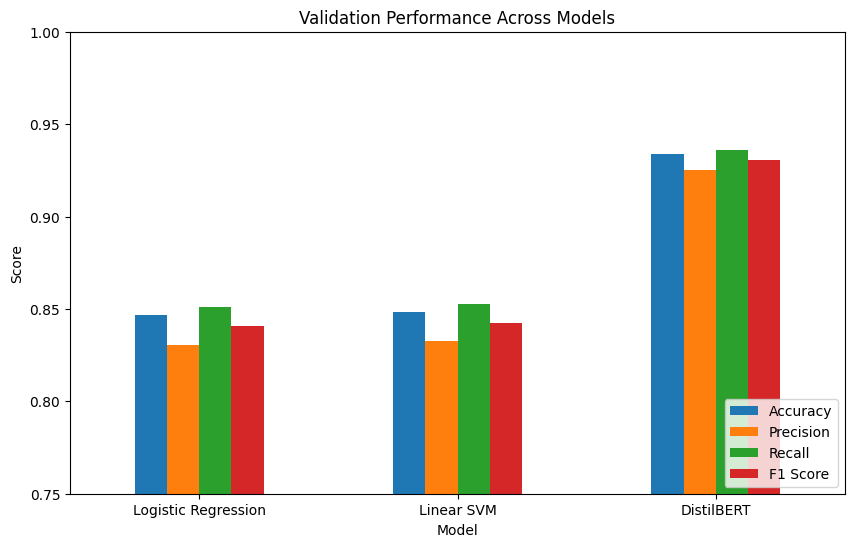

In [6]:
comparison.set_index("Model")[[
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Validation Performance Across Models")
plt.ylabel("Score")
plt.ylim(0.75, 1.0)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

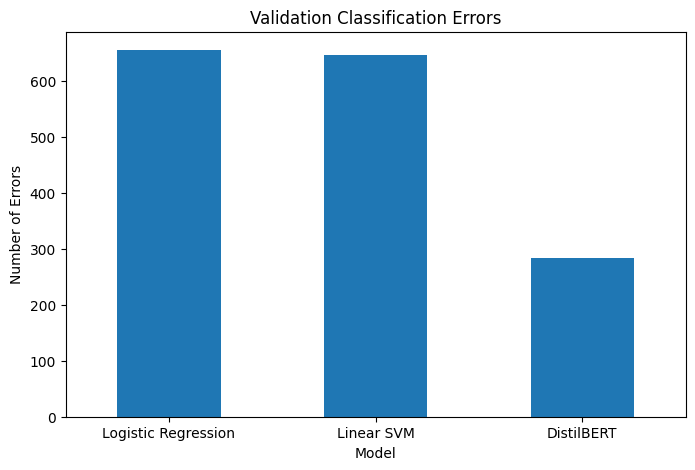

In [7]:
error_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Linear SVM",
        "DistilBERT"
    ],
    "Total Errors": [
        656,
        648,
        284
    ]
})

error_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(8, 5),
    legend=False
)

plt.title("Validation Classification Errors")
plt.ylabel("Number of Errors")
plt.xticks(rotation=0)
plt.show()

In [8]:
svm_errors = 648
distilbert_errors = 284

error_reduction = (
    (svm_errors - distilbert_errors)
    / svm_errors
) * 100

print(f"Error reduction vs SVM: {error_reduction:.2f}%")

Error reduction vs SVM: 56.17%


# Full Model Comparison

This notebook compares the three sarcasm detection models developed in the project:

- Logistic Regression with TF-IDF
- Linear SVM with TF-IDF
- DistilBERT

All models are evaluated on the same validation split to ensure a fair comparison.

## Overall Performance

The classical TF-IDF models achieved strong validation performance of approximately 85% accuracy. Logistic Regression and Linear SVM performed almost identically, indicating that the TF-IDF feature representation captured a substantial amount of useful lexical information.

DistilBERT significantly outperformed both classical models.

The transformer model achieved:

- **Accuracy:** 93.36%
- **Precision:** 92.51%
- **Recall:** 93.61%
- **F1-score:** 93.06%

This represents an improvement of roughly eight percentage points over the classical baselines.

## Classification Error Comparison

The models produced the following numbers of validation errors:

- Logistic Regression: **656**
- Linear SVM: **648**
- DistilBERT: **284**

DistilBERT reduced the number of classification errors by approximately **56% compared with Linear SVM**.

This large decrease suggests that contextual language representations provide a significant advantage for sarcasm detection.

## Interpretation

The classical TF-IDF models primarily rely on word and phrase frequency patterns. They perform well when sarcasm can be identified through recurring lexical cues or stylistic patterns.

DistilBERT, by contrast, generates contextual representations in which the meaning of a word depends on the surrounding text. This makes it better suited to detecting semantic incongruity, subtle phrasing, and contextual signals associated with sarcasm.

The results therefore suggest that the largest performance improvement comes from changing the text representation rather than switching between different linear classifiers.

## Final Model Selection

Based on validation performance, **DistilBERT is selected as the final model**.

It achieves the highest accuracy, precision, recall, and F1-score while also producing substantially fewer classification errors than the classical models.

The next stage of the project will evaluate DistilBERT once on the untouched test set to obtain the final unbiased estimate of model performance.

## Reusable Prediction Pipeline

After final model evaluation, the fine-tuned DistilBERT model and tokenizer are saved for inference.

A reusable prediction script is implemented in `src/predict.py`. The script accepts unseen text, tokenizes it using the same DistilBERT tokenizer used during training, performs inference with the fine-tuned model, and returns:

- the predicted class,
- either **Sarcastic** or **Not Sarcastic**,
- and the model's confidence score.

The prediction script allows the trained NLP model to be used independently of the training notebooks and makes the repository easier to reproduce and demonstrate.

Example usage:

`python src/predict.py "Oh great, another Monday morning."`

This separates model development from inference and turns the project from a notebook-based experiment into a reusable NLP application.

## Generalization Limitation

Although the final DistilBERT model achieved strong performance on the held-out test set, manual inference experiments revealed an important limitation.

The model occasionally assigns high-confidence sarcastic predictions to ordinary news-style headlines. This suggests that the classifier may have learned stylistic or source-specific patterns present in the training dataset in addition to genuine indicators of sarcasm.

Because the sarcastic and non-sarcastic examples originate from different publication styles, the model's performance on the held-out dataset may be higher than its ability to generalize to completely new domains.

The confidence score should therefore not be interpreted as a calibrated probability of sarcasm. High-confidence predictions can still be incorrect when the input differs from the training distribution.

Future work could evaluate the model on external sarcasm datasets or fine-tune it using a mixture of news, social media, Reddit, and conversational sarcasm examples.